# P05 — Integração e clusterização das células do pré-processamento novo

As células aprovadas em P03 (padrão de 200 UMIs), sem os doublets removidos
em P04 e com as contagens corrigidas pelo SoupX, passam pelo processamento V3
de A04: genes variáveis `seurat_v3` por biblioteca, PCA sobre a lognorm
escalonada, Harmony por biblioteca, vizinhança em 15 dimensões, Leiden 0,5.

Antes, o filtro de genes do capítulo: genes detectados em pelo menos 20
células **do conjunto** (não por amostra), comparado com o `min_cells = 3`
da V3.

Duas perguntas sobre o padrão: onde caem (1) as células de **baixa
profundidade** — barcodes de 200–500 UMIs que o Cell Ranger não chamou e
que entraram por terem perfil de célula — e (2) as células do Cell Ranger que
o QC com MAD por biblioteca descartaria? Entram nos clusters existentes, como
células comuns, ou formam clusters próprios, como faria material de baixa
qualidade?

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import time
import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp

from functions import config, fmt as F, io, pipeline as pl, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
sc.settings.verbosity = 0

NB = "P05_integracao"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK

In [2]:
src = config.HEAVY_OUT / "P04_ambiente_e_doublets" / "celulas_aprovadas.h5ad"
a = ad.read_h5ad(src)
qc = io.load_data("P03_qc_best_practices", "qc_candidatos")
aprov = set(qc.loc[qc["passa"], "library_id"] + "|" + qc.loc[qc["passa"], "barcode"])
assert aprov == set(a.obs_names), "as células de P04 não são as aprovadas na versão atual de P03"
def _bool(s):
    return s.astype(str).str.lower().isin(["true", "1"]).to_numpy()


rem = _bool(a.obs["doublet_removido"])
print(f"{F.n(a.n_obs)} células aprovadas em P03 (conjunto conferido); {F.n(rem.sum())} doublets removidos "
      f"(scDblFinder calibrado pela taxa do 10x + T + B validados)")
a = a[~rem].copy()
print(f"{F.n(a.n_obs)} células × {F.n(a.n_vars)} genes · {plotting.N_DESIGN}")

36.979 células aprovadas em P03 (conjunto conferido); 1.732 doublets removidos (scDblFinder calibrado pela taxa do 10x + T + B validados)


35.247 células × 38.606 genes · 14 bibliotecas · 7 pacientes


## 1. Filtro de genes

In [3]:
det = np.asarray((a.X > 0).sum(axis=0)).ravel()
regras = {f"min_cells = {m}": det >= m for m in (1, 3, config.BP_MIN_CELLS)}
sym = a.var["gene_symbol"].astype(str).to_numpy()
gen = pd.DataFrame({k: {"genes": int(v.sum()),
                        "citocinas mantidas (de 16)": int(sum(v[sym == g].any() for g in config.CYTOKINES))}
                    for k, v in regras.items()}).T
cit_det = pd.Series({g: int(det[sym == g].max()) if (sym == g).any() else 0 for g in config.CYTOKINES}, name="células")
perdidas = cit_det[cit_det < config.BP_MIN_CELLS]
io.save_table(gen, NB, "filtro_de_genes", description="Genes mantidos por regra de filtro global")
print(f"citocinas abaixo de {config.BP_MIN_CELLS} células: " + "; ".join(f"{g} ({n})" for g, n in perdidas.items()))
gen

citocinas abaixo de 20 células: IL31 (11); IL3 (0)


,genes,citocinas mantidas (de 16)
min_cells = 1,33663,15
min_cells = 3,31560,15
min_cells = 20,26053,14


## 2. Processamento V3

In [4]:
keep = regras[f"min_cells = {config.BP_MIN_CELLS}"]
b = a[:, keep].copy()
b.layers["counts"] = b.X.copy()                    # SoupX (inteiras): entram nos HVGs e na lognorm
b.var["gene_ids"] = b.var_names.to_numpy()
b.var_names = pd.Index(pl.symbol_map().reindex(b.var["gene_ids"]).to_numpy())
assert b.var_names.is_unique
b.obs["library_id"] = pd.Categorical(b.obs["library_id"].astype(str), sorted(LIBS))
pl.add_design(b.obs)
b.var["mt"] = b.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(b, qc_vars=["mt"], inplace=True)

t0 = time.time()
hvg = pl.select_hvg(b)
res = pl.run_variant(b, "V3", hvg)
sem = pl.leiden_sweep(res, [config.LEIDEN_RESOLUTION], seeds=(1,))
ari_seed = pl.clustering_agreement(res.obs["leiden"], sem.iloc[:, 0])["ARI"]
print(f"V3 em {time.time() - t0:.0f} s; ARI entre duas sementes do Leiden: {F.f(ari_seed, 2)}")
obs = res.obs
cl = obs["leiden"].astype(str)
CL = sorted(cl.unique(), key=int)

  V3: 35,247 células × 26,053 genes no universo; PCA sobre lognorm escalonada; variância em 50 PCs 0.172; 11 clusters; Harmony: Converged after 4 iterations


V3 em 146 s; ARI entre duas sementes do Leiden: 0,55


## 3. Onde caem as células que o padrão acrescenta

In [5]:
obs["baixa_profundidade"] = _bool(obs["baixa_profundidade"])
obs["so_no_padrao"] = _bool(obs["cellranger"]) & ~_bool(obs["passa_mad"])
glob_rec = obs["so_no_padrao"].mean()
glob_bp = obs["baixa_profundidade"].mean()
por_cl = pd.DataFrame({
    "células": cl.value_counts().reindex(CL),
    "baixa profundidade": obs.groupby(cl)["baixa_profundidade"].sum().reindex(CL),
    "fração baixa profundidade": obs.groupby(cl)["baixa_profundidade"].mean().reindex(CL),
    "só no padrão": obs.groupby(cl)["so_no_padrao"].sum().reindex(CL),
    "fração só no padrão": obs.groupby(cl)["so_no_padrao"].mean().reindex(CL),
    "marcadas pelo scDblFinder (limiar padrão)": obs.groupby(cl)["scdbl_doublet"].apply(lambda s: _bool(s).mean()).reindex(CL),
    "UMIs medianos": obs.groupby(cl)["total_counts"].median().reindex(CL),
    "genes medianos": obs.groupby(cl)["n_genes_by_counts"].median().reindex(CL),
    "fração T (marcadores)": obs.groupby(cl)["frac_T"].median().reindex(CL),
    "fração B (marcadores)": obs.groupby(cl)["frac_B"].median().reindex(CL),
    "fração mieloide (marcadores)": obs.groupby(cl)["frac_mieloide"].median().reindex(CL),
})
por_cl["enriquecimento baixa profundidade"] = por_cl["fração baixa profundidade"] / glob_bp
por_cl["enriquecimento só no padrão"] = por_cl["fração só no padrão"] / glob_rec
io.save_table(por_cl, NB, "clusters", description="Clusters da V3 nova: células acrescentadas pelo padrão, QC e linhagem")
rec_lib = pd.DataFrame({"baixa profundidade": obs.groupby("library_id")["baixa_profundidade"].sum(),
                        "só no padrão (MAD descartaria)": obs.groupby("library_id")["so_no_padrao"].sum(),
                        "células": obs.groupby("library_id").size()}).reindex(LIBS)
io.save_table(rec_lib, NB, "acrescentadas_por_biblioteca", description="Células acrescentadas pelo padrão de 200 UMIs, por biblioteca")
for nome, col in (("baixa profundidade", "fração baixa profundidade"), ("só no padrão", "fração só no padrão")):
    print(f"{nome}: {F.n(por_cl[nome].sum())} células; clusters com mais de 50% delas: "
          + (", ".join(c for c in CL if por_cl.loc[c, col] > 0.5) or "nenhum")
          + f"; maior fração: cluster {por_cl[col].idxmax()} ({F.pct(por_cl[col].max(), 0)} de {F.n(por_cl.loc[por_cl[col].idxmax(), 'células'])} células)")
display(rec_lib)
por_cl.round(3)

baixa profundidade: 789 células; clusters com mais de 50% delas: nenhum; maior fração: cluster 7 (50% de 1.366 células)
só no padrão: 1.262 células; clusters com mais de 50% delas: nenhum; maior fração: cluster 7 (23% de 1.366 células)


,baixa profundidade,só no padrão (MAD descartaria),células
library_id,,,
CTH92_NS,21,24,860
CTH92_ML,50,0,1569
CTH94_NS,100,286,5669
CTH94_ML,10,20,535
CTH97_NS,33,50,1545
CTH97_ML,197,0,4658
PB20_NS,8,21,626
PB20_ML,21,36,841
PB21_NS,81,180,3790


,células,baixa profundidade,fração baixa profundidade,só no padrão,fração só no padrão,marcadas pelo scDblFinder (limiar padrão),UMIs medianos,genes medianos,fração T (marcadores),fração B (marcadores),fração mieloide (marcadores),enriquecimento baixa profundidade,enriquecimento só no padrão
leiden,,,,,,,,,,,,,
0,8572,1,0.000,100,0.012,0.067,11310.0,3465.5,0.002,0.000,0.000,0.005,0.326
1,6573,93,0.014,429,0.065,0.007,6131.0,1726.0,0.003,0.000,0.000,0.632,1.823
2,6269,0,0.000,28,0.004,0.034,11780.0,3513.0,0.002,0.000,0.000,0.000,0.125
3,4850,1,0.000,172,0.035,0.017,8714.0,2608.0,0.003,0.000,0.000,0.009,0.990
4,2590,2,0.001,67,0.026,0.019,7797.0,2425.0,0.003,0.000,0.000,0.034,0.722
5,1934,3,0.002,53,0.027,0.023,7566.5,2674.0,0.003,0.000,0.000,0.069,0.765
6,1437,0,0.000,25,0.017,0.046,7016.0,2025.0,0.003,0.000,0.000,0.000,0.486
7,1366,680,0.498,310,0.227,0.001,504.0,342.5,0.002,0.000,0.000,22.238,6.338
8,1265,4,0.003,57,0.045,0.025,8245.0,3137.0,0.003,0.000,0.000,0.141,1.258


## 4. Concordância com a V3 de A04 (pré-processamento antigo)

In [6]:
ig = ad.read_h5ad(io.data_path("A04_processamento_integracao", "reseq_integrado", "h5ad"), backed="r")
antiga = pd.Series(ig.obs["leiden"].astype(str).to_numpy(), index=ig.obs["cell_key"].to_numpy())
ig.file.close()
comum = obs.index.intersection(antiga.index)
c_ = pl.clustering_agreement(antiga.reindex(comum), cl.reindex(comum))
mf = pl.matched_fraction(antiga.reindex(comum), cl.reindex(comum))
conc = pd.DataFrame({"células em comum": [len(comum)], "só no objeto novo": [len(obs.index.difference(antiga.index))],
                     "só no objeto de A04": [len(antiga.index.difference(obs.index))],
                     "ARI": [c_["ARI"]], "NMI": [c_["NMI"]], "células no cluster pareado": [mf],
                     "ARI de referência entre sementes": [ari_seed]}, index=["V3 nova × V3 de A04"]).T
io.save_table(conc, NB, "concordancia_com_a04", description="Agrupamento novo × V3 de A04 nas células em comum")
conc

,V3 nova × V3 de A04
células em comum,32829.000000
só no objeto novo,2418.000000
só no objeto de A04,2235.000000
ARI,0.558850
NMI,0.635121
células no cluster pareado,0.754424
ARI de referência entre sementes,0.548747


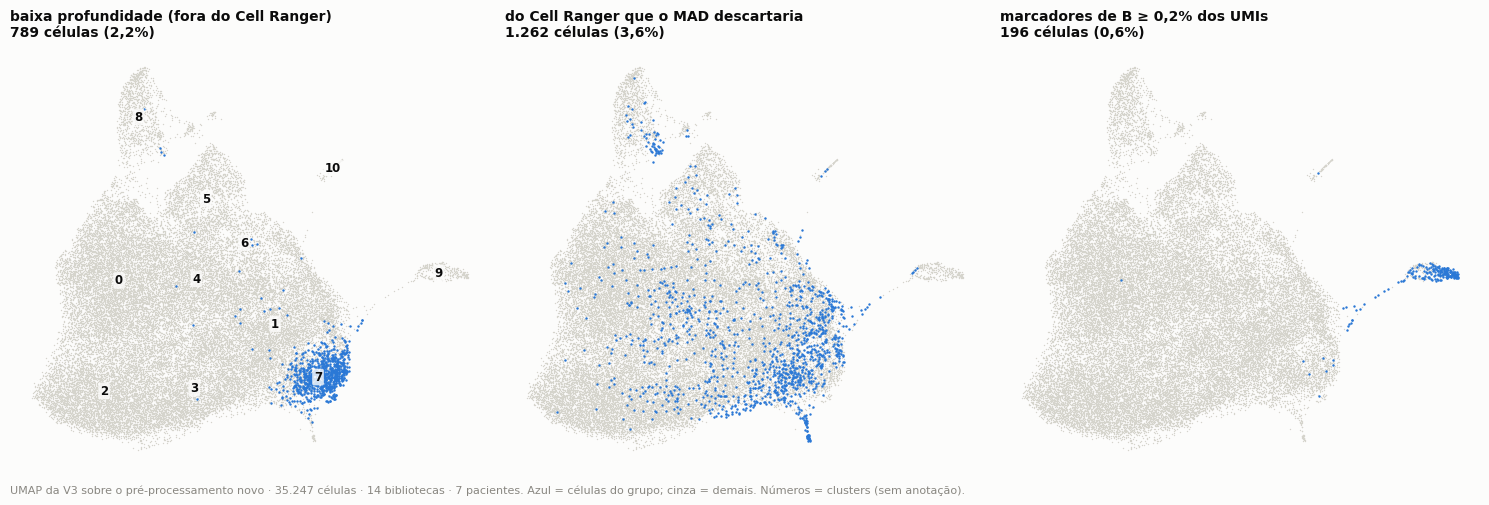

In [7]:
um = res.obsm["X_umap"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.9))
paineis = [("baixa profundidade (fora do Cell Ranger)", obs["baixa_profundidade"].to_numpy()),
           ("do Cell Ranger que o MAD descartaria", obs["so_no_padrao"].to_numpy()),
           ("marcadores de B ≥ 0,2% dos UMIs", (obs["frac_B"] >= 0.002).to_numpy())]
for ax, (nome, m) in zip(axes, paineis):
    ax.scatter(um[:, 0], um[:, 1], s=1, c=plotting.CONTEXT, lw=0, rasterized=True)
    ax.scatter(um[m, 0], um[m, 1], s=3, c=plotting.ACCENT, lw=0, rasterized=True)
    ax.set_title(f"{nome}\n{F.n(m.sum())} células ({F.pct(m.mean(), 1)})", fontsize=10)
    plotting._umap_axes(ax)
for c in CL:
    mc = (cl == c).to_numpy()
    axes[0].text(np.median(um[mc, 0]), np.median(um[mc, 1]), c, ha="center", va="center", fontsize=8.5,
                 fontweight="bold", color=INK["primary"],
                 bbox=dict(boxstyle="round,pad=0.15", fc=INK["surface"], ec="none", alpha=0.8))
plotting.note(fig, f"UMAP da V3 sobre o pré-processamento novo · {F.n(len(obs))} células · {plotting.N_DESIGN}. "
                   "Azul = células do grupo; cinza = demais. Números = clusters (sem anotação).", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "umap_qualidade", description="UMAP da V3 nova: células acrescentadas pelo padrão e sinal de B",
                 data=por_cl.rename_axis("cluster").reset_index(), data_index=False)
plt.show()

## 5. Citocinas

In [8]:
C = b[:, [g for g in config.CYTOKINES if g in b.var_names]].layers["counts"]
C = pd.DataFrame(C.toarray() if sp.issparse(C) else C, index=b.obs_names,
                 columns=[g for g in config.CYTOKINES if g in b.var_names])
pos_tab = pd.DataFrame({"≥ 1 UMI": (C >= 1).sum(), "≥ 2 UMIs": (C >= 2).sum(),
                        "≥ 1 UMI entre as de baixa profundidade": (C[obs["baixa_profundidade"].to_numpy()] >= 1).sum(),
                        "≥ 1 UMI entre as só no padrão": (C[obs["so_no_padrao"].to_numpy()] >= 1).sum()})
io.save_table(pos_tab, NB, "citocinas", description="Células positivas para citocinas (contagens SoupX) por grupo")
display(pos_tab)

,≥ 1 UMI,≥ 2 UMIs,≥ 1 UMI entre as de baixa profundidade,≥ 1 UMI entre as só no padrão
IFNG,962,385,8,2
TNF,2071,504,1,20
IL2,74,17,0,2
IL4,92,8,0,1
IL5,286,35,0,3
IL9,122,67,1,0
IL10,48,6,0,1
IL13,61,20,1,2
IL17A,74,48,1,0
IL17F,266,85,8,0


### Por que o teste de perfil não vale para as células do Cell Ranger

O teste de P01 compara cada barcode com o perfil médio das células da
biblioteca e foi calibrado na profundidade dos barcodes extras. Aplicado às
células do Cell Ranger, ele reprova uma parte delas; se fossem gotas vazias,
teriam menos transcrito de citocina e se concentrariam em poucos clusters.

In [9]:
crm = _bool(obs["cellranger"])
reprov = crm & ~_bool(obs["parece_celula"])
cyt_any = (C[[g for g in ["IFNG", "TNF", "IL17F", "IL22", "IL9", "IL2"] if g in C.columns]] >= 1).any(axis=1).to_numpy()
frac_cl = pd.Series(reprov).groupby(cl.to_numpy()).mean()
teste = pd.DataFrame({
    "células": [int(reprov.sum()), int((crm & ~reprov).sum())],
    "UMIs medianos": [obs.loc[reprov, "total_counts"].median(), obs.loc[crm & ~reprov, "total_counts"].median()],
    "positivas para IFNG, TNF, IL17F, IL22, IL9 ou IL2": [cyt_any[reprov].mean(), cyt_any[crm & ~reprov].mean()],
}, index=["reprovadas pelo teste", "aprovadas pelo teste"])
io.save_table(teste, NB, "teste_de_perfil_nas_celulas_do_cellranger",
              description="Células do Cell Ranger que o teste de perfil reprovaria: o que são")
print(f"fração reprovada por cluster: de {F.pct(frac_cl.min(), 0)} a {F.pct(frac_cl.max(), 0)}")
teste.round(3)

fração reprovada por cluster: de 1% a 75%


,células,UMIs medianos,"positivas para IFNG, TNF, IL17F, IL22, IL9 ou IL2"
reprovadas pelo teste,8512,7242.5,0.112
aprovadas pelo teste,25946,9777.5,0.092


## 6. Objeto integrado

In [10]:
out = b
out.X = pl.lognorm(out.layers["counts"])
for k in ("X_pca", "X_emb_harmony", "X_umap"):
    out.obsm[k] = np.asarray(res.obsm[k], dtype=np.float32)
out.obsp["connectivities"] = res.obsp["connectivities"]
out.obsp["distances"] = res.obsp["distances"]
out.uns["neighbors"] = {"connectivities_key": "connectivities", "distances_key": "distances",
                        "params": {k: pl._plain(v) for k, v in res.uns["neighbors"]["params"].items()}}
out.obs["leiden"] = pd.Categorical(cl.to_numpy(), CL)
out.obs["so_no_padrao"] = obs["so_no_padrao"].to_numpy()
out.obs["baixa_profundidade"] = obs["baixa_profundidade"].to_numpy()
out.var["highly_variable"] = out.var_names.isin(res.var_names)
for c in out.obs.columns:
    if out.obs[c].dtype == object:
        out.obs[c] = out.obs[c].astype(str)
out.uns = {k: v for k, v in out.uns.items() if k in ("neighbors", "soupx_rho")}
out.uns["reseq_raw"] = {"filtro_genes_min_cells": int(config.BP_MIN_CELLS), "contagens": "SoupX (layers['counts']); brutas em layers['counts_raw']",
                        "padrao": f"mínimo de {config.QC_MIN_UMIS} UMIs; fora do Cell Ranger, só com perfil de célula "
                                  "(obs['baixa_profundidade'])",
                        "doublets": "removidos: scDblFinder calibrado pela taxa do 10x + T+B validados"}
caminho = io.save_data(out, NB, "reseq_raw_integrado",
                       description="Pré-processamento a partir da matriz raw (best practices): células aprovadas, contagens SoupX, V3")
print(f"gravado: {caminho} ({caminho.stat().st_size / 1e6:.0f} MB)")

[io] inalterado, não regravado: reseq_raw_integrado__v2.h5ad
gravado: /mnt/SATA/singleCellTaru/dataReseq/P05_integracao/reseq_raw_integrado__v2.h5ad (698 MB)


## Problemas encontrados

In [11]:
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       0
MINOR       0
INFO        0


severity,location,problem,evidence,impact,recommendation


## Conclusão

O filtro global do capítulo (gene em ≥ 20 células) mantém 26.053 genes e 14
das 16 citocinas (saem IL31, com 11 células, e IL3). Sem os 1.732 doublets
removidos, ficam 35.247 células; a V3 dá 11 clusters, com a mesma estrutura
da V3 de A04 (ARI 0,56 nas células em comum, igual ao ARI entre duas
sementes do Leiden, 0,55; 75% das células no cluster pareado).

**As células de baixa profundidade não se misturam:** 680 das 789 (86%)
formam, com outras células pobres, o cluster 7 (1.366 células, mediana de
504 UMIs e 342 genes) — um cluster técnico, de baixo conteúdo. As 1.262
células do Cell Ranger que o MAD descartaria se espalham mais, com 310 delas
no mesmo cluster 7. Na anotação, o cluster 7 deve ser marcado como técnico,
e `obs["baixa_profundidade"]` permite tirar essas células de qualquer
análise que dependa de contagens.

O teste de perfil, se aplicado às células do Cell Ranger, reprovaria 8.512
delas, mais positivas para citocina que as demais e concentradas em alguns
clusters (até 75% de um cluster) — por isso ele vale só para os barcodes fora
da chamada do Cell Ranger.

In [12]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

11 artefatos gravados por este notebook:
                                     name   kind
              so_no_padrao_por_biblioteca  table
                      reseq_raw_integrado   h5ad
                          filtro_de_genes  table
                                 clusters  table
             acrescentadas_por_biblioteca  table
                     concordancia_com_a04  table
                       fig_umap_qualidade figure
                       fig_umap_qualidade  table
                                citocinas  table
teste_de_perfil_nas_celulas_do_cellranger  table
                                   issues  table
